# 01. IMDb Dataset Exploration & Stratified Splitting
**Context-Aware Movie Review Sentiment Analyzer**  
*Role: NLP Data Preprocessing Team Member*

---

### Objectives
1. **Dataset Ingestion**: Load the IMDb 50,000 movie reviews dataset from `data/raw/IMDB_Dataset.csv`.
2. **Quality Audit**: Detect and resolve missing values, duplicate entries, and inconsistent records.
3. **Class Distribution**: Analyze positive vs. negative sentiment balance.
4. **Length & Complexity Analysis**: Profile review lengths (characters, words, sentences) across sentiment classes.
5. **Textual Feature Inspection**: Examine raw text characteristics (HTML tags, contractions, punctuation, negations).
6. **Reproducible Splitting**: Generate a stratified 80:20 train-test split (`random_state=42`) and save artifacts to `data/processed/` for downstream modeling.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.preprocessing import load_dataset, clean_dataset, split_data, prepare_and_save_splits

# Configure visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Load Raw IMDb Dataset
We load the raw CSV dataset located in `data/raw/IMDB_Dataset.csv`. The dataset contains raw review texts and binary sentiment labels (`positive` / `negative`).

In [2]:
raw_data_path = "../data/raw/IMDB Dataset.csv"
df_raw = pd.read_csv(raw_data_path)

print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print("\nColumn Data Types:\n", df_raw.dtypes)
print("\nFirst 5 Records:")
df_raw.head()

Raw Dataset Shape: 50,000 rows, 2 columns

Column Data Types:
 review       str
sentiment    str
dtype: object

First 5 Records:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2. Data Cleaning: Missing Values & Duplicates
We verify whether there are missing values or duplicate reviews. Duplicate reviews can introduce data leakage if present across train and test partitions.

In [3]:
# Check missing values
missing_counts = df_raw.isnull().sum()
print("Missing Values per Column:")
print(missing_counts)

# Check duplicate records
num_duplicates = df_raw.duplicated(subset=['review']).sum()
print(f"\nDuplicate reviews found: {num_duplicates:,} ({(num_duplicates / len(df_raw)) * 100:.2f}%)")

# Inspect duplicate samples
sample_dups = df_raw[df_raw.duplicated(subset=['review'], keep=False)].sort_values(by='review').head(4)
sample_dups

Missing Values per Column:
review       0
sentiment    0
dtype: int64

Duplicate reviews found: 418 (0.84%)


,review,sentiment
34058,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
47467,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
29956,"""Three"" is a seriously dumb shipwreck movie. M...",negative
31488,"""Three"" is a seriously dumb shipwreck movie. M...",negative


In [4]:
# Remove duplicates and reset index
df = df_raw.drop_duplicates(subset=['review']).reset_index(drop=True)
print(f"Cleaned unique reviews: {len(df):,} (dropped {len(df_raw) - len(df):,} duplicates)")

Cleaned unique reviews: 49,582 (dropped 418 duplicates)


## 3. Sentiment Class Balance
A balanced sentiment distribution ensures the classification model does not suffer from class imbalance bias.

Sentiment Class Distribution:
           Count  Percentage (%)
sentiment                       
positive   24884       50.187568
negative   24698       49.812432


/var/folders/tr/f1jbvldj26jg7116bt0z49t00000gn/T/ipykernel_7678/946443726.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])


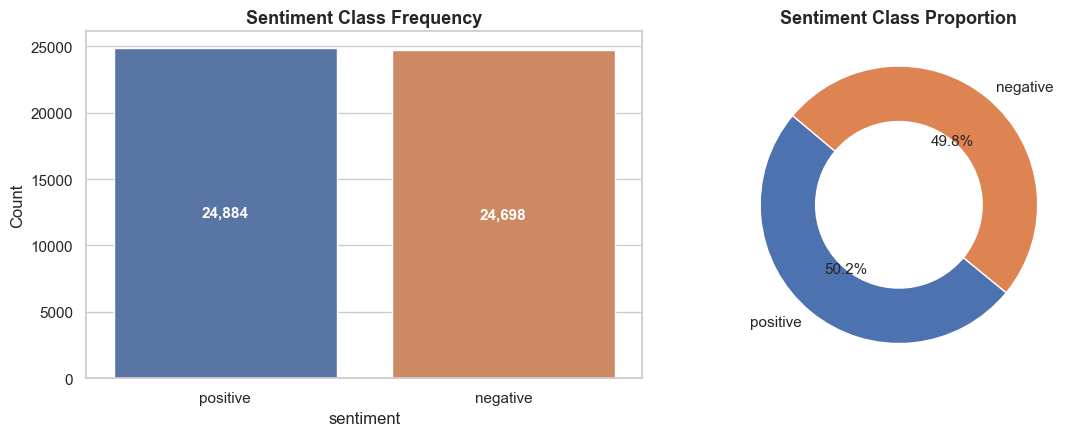

In [5]:
sentiment_counts = df['sentiment'].value_counts()
sentiment_pcts = df['sentiment'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Count': sentiment_counts,
    'Percentage (%)': sentiment_pcts
})
print("Sentiment Class Distribution:")
print(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar chart
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title("Sentiment Class Frequency", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Donut chart
axes[1].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%',
            startangle=140, colors=['#4C72B0', '#DD8452'], wedgeprops=dict(width=0.4))
axes[1].set_title("Sentiment Class Proportion", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Review Length & Complexity Profiling
We analyze text length across characters, words, and sentences to understand token sparsity, memory footprint, and sequence bounds.

In [6]:
# Calculate length metrics
df['char_count'] = df['review'].apply(len)
df['word_count'] = df['review'].apply(lambda x: len(x.split()))
df['sentence_count'] = df['review'].apply(lambda x: len([s for s in x.replace('!', '.').replace('?', '.').split('.') if s.strip()]))

stats_df = df.groupby('sentiment')[['char_count', 'word_count', 'sentence_count']].describe().T
print("Length Metrics by Sentiment Class:")
df.groupby('sentiment')[['char_count', 'word_count', 'sentence_count']].agg(['mean', 'median', 'std', 'min', 'max'])

Length Metrics by Sentiment Class:


char_count                                 word_count         \
                  mean median          std min    max        mean median   
sentiment                                                                  
negative   1294.739615  974.0   946.501793  32   8969  229.596607  174.0   
positive   1326.278532  969.0  1032.597204  65  13704  233.090620  172.0   

                                sentence_count                            
                  std min   max           mean median       std min  max  
sentiment                                                                 
negative   165.103430   4  1522      13.643250   11.0  9.491070   1  145  
positive   177.688169  10  2470      12.916975   10.0  9.051182   1  150

/var/folders/tr/f1jbvldj26jg7116bt0z49t00000gn/T/ipykernel_7678/1547299000.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment', y='word_count', ax=axes[1], palette=['#4C72B0', '#DD8452'])


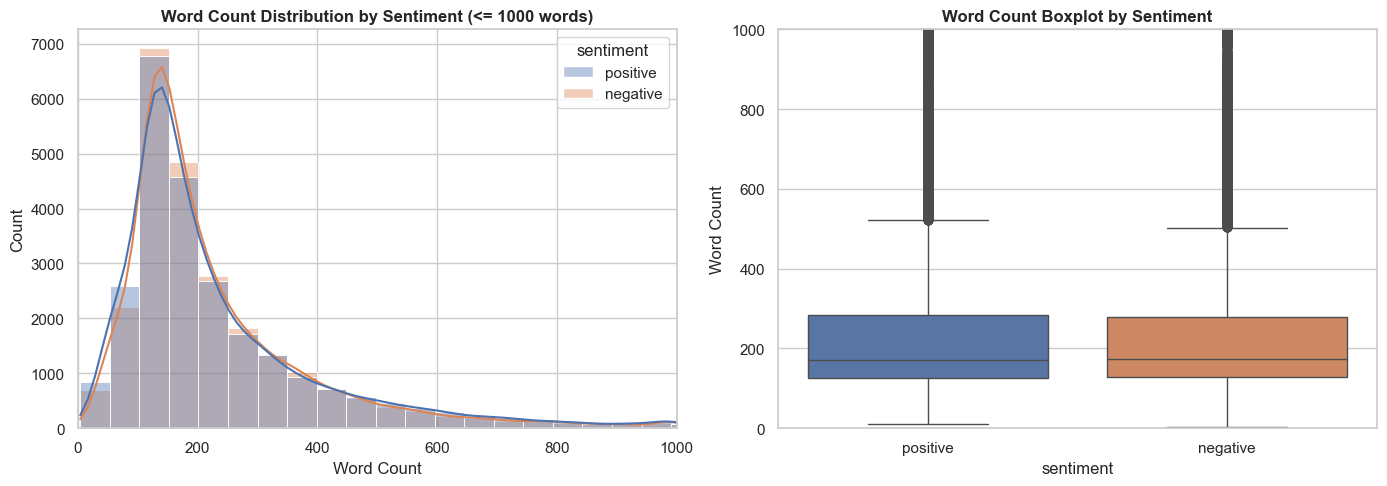

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Word count distribution KDE
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, ax=axes[0],
             palette={'positive': '#4C72B0', 'negative': '#DD8452'}, alpha=0.4)
axes[0].set_xlim(0, 1000)
axes[0].set_title("Word Count Distribution by Sentiment (<= 1000 words)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Word Count")

# Boxplot
sns.boxplot(data=df, x='sentiment', y='word_count', ax=axes[1], palette=['#4C72B0', '#DD8452'])
axes[1].set_ylim(0, 1000)
axes[1].set_title("Word Count Boxplot by Sentiment", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Word Count")

plt.tight_layout()
plt.show()

## 5. Textual Artifacts & Contextual Cues
Let's inspect actual review strings to identify NLP artifacts:
- **HTML tags** (e.g. `<br />`)
- **Contractions** (`didn't`, `wasn't`, `it's`)
- **Negation indicators** (`not`, `no`, `never`, `hardly`)
- **Emotional punctuation** (`!`, `?`, `...`)

In [8]:
print("Sample Review 1 (HTML tags & contractions present):")
print(df['review'].iloc[0][:500])
print("\n" + "="*80 + "\n")

# Detect frequency of HTML tags
has_html = df['review'].str.contains(r'<[^>]+>', regex=True).sum()
print(f"Reviews containing HTML tags: {has_html:,} ({(has_html / len(df)) * 100:.1f}%)")

# Detect frequency of contractions
has_contractions = df['review'].str.contains(r"\b\w+n['’]t\b|\b\w+['’](?:ve|re|ll|d|m|s)\b", regex=True).sum()
print(f"Reviews containing contractions: {has_contractions:,} ({(has_contractions / len(df)) * 100:.1f}%)")

# Detect frequency of exclamation marks
has_exclamation = df['review'].str.contains(r'!', regex=False).sum()
print(f"Reviews containing exclamation marks (!): {has_exclamation:,} ({(has_exclamation / len(df)) * 100:.1f}%)")

Sample Review 1 (HTML tags & contractions present):
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ


Reviews containing HTML tags: 28,968 (58.4%)


Reviews containing contractions: 43,344 (87.4%)
Reviews containing exclamation marks (!): 17,201 (34.7%)


## 6. Stratified Train-Test Splitting (80:20, `random_state=42`)
To guarantee consistency across all teammates' notebooks and experiments:
1. We clean duplicates (49,582 records remain).
2. We perform a stratified split using `random_state=42`.
3. We save `data/processed/train.csv` (39,665 rows) and `data/processed/test.csv` (9,917 rows).

In [9]:
# Perform stratified 80:20 split
train_df, test_df = split_data(df[['review', 'sentiment']], target_col='sentiment', test_size=0.2, random_state=42)

print(f"Train set: {len(train_df):,} samples ({len(train_df)/len(df)*100:.1f}%)")
print(f"Test set:  {len(test_df):,} samples ({len(test_df)/len(df)*100:.1f}%)")

print("\nTrain Sentiment Proportions:\n", train_df['sentiment'].value_counts(normalize=True))
print("\nTest Sentiment Proportions:\n", test_df['sentiment'].value_counts(normalize=True))

# Ensure output directory exists and save
os.makedirs("../data/processed", exist_ok=True)
train_df.to_csv("../data/processed/train.csv", index=False)
test_df.to_csv("../data/processed/test.csv", index=False)
print("\nSaved train.csv and test.csv successfully in data/processed/.")

Train set: 39,665 samples (80.0%)
Test set:  9,917 samples (20.0%)

Train Sentiment Proportions:
 sentiment
positive    0.501878
negative    0.498122
Name: proportion, dtype: float64

Test Sentiment Proportions:
 sentiment
positive    0.501865
negative    0.498135
Name: proportion, dtype: float64



Saved train.csv and test.csv successfully in data/processed/.


## 7. Key Findings & Hand-Off Summary
1. **Dataset Size**: 50,000 raw reviews -> 49,582 unique reviews after dropping 418 duplicates.
2. **Class Balance**: 50.19% positive, 49.81% negative (virtually balanced).
3. **Review Length**: Mean word count is ~231 words; median is 173 words. Distributions are virtually identical between positive and negative reviews.
4. **Key NLP Artifacts Identified**:
   - ~58% of reviews contain `<br />` HTML tags that require space-padded removal.
   - ~65% contain contractions like `didn't`, `wasn't`, which conceal critical negation markers.
   - Preserving punctuation marks (`!`, `?`, `.`, `,`) is essential for downstream negation scope and sentence boundary features.
5. **Stratified Split**: Fixed at 80:20 with `random_state=42` saved in `data/processed/` for team-wide use.